# Import Library & New Dataset

In [ ]:
import os
import shutil
import random
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
import torch
import torch.nn as nn
import timm
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import torch.optim as optim
from sklearn.metrics import classification_report
from pathlib import Path

In [ ]:
import kagglehub

# Skin cancer ISIC, 9 classes (2,357 images), downloaded once to the kagglehub cache
RAW_DIR = Path(kagglehub.dataset_download("nodoubttome/skin-cancer9-classesisic")) / "Skin cancer ISIC The International Skin Imaging Collaboration"

Downloading...
From (original): https://drive.google.com/uc?export=download&id=1jjKJZQXs7AsuBsNQq0S5xfpBWL1XzmLY
From (redirected): https://drive.google.com/uc?export=download&id=1jjKJZQXs7AsuBsNQq0S5xfpBWL1XzmLY&confirm=t&uuid=bd64487e-6383-4f2a-8e8c-ac873a2fbd14
To: /content/New Dataset Skin Cancer ISIC Final.zip
100%|██████████| 433M/433M [00:02<00:00, 164MB/s]


'New Dataset Skin Cancer ISIC Final.zip'

In [ ]:
# The Kaggle copy only has Train/Test, so pool both and split again 70/20/10 into
# train/test/val folders in the cache (outside the repo), the layout used below.
SKIN_DIR = Path.home() / ".cache" / "ml-notebooks" / "skin-cancer"

if not SKIN_DIR.exists():
    tmp_dir = SKIN_DIR.with_name(SKIN_DIR.name + ".tmp")
    shutil.rmtree(tmp_dir, ignore_errors=True)
    random.seed(42)
    for class_dir in sorted(p for p in (RAW_DIR / "Train").iterdir() if p.is_dir()):
        images = sorted(class_dir.glob("*")) + sorted((RAW_DIR / "Test" / class_dir.name).glob("*"))
        random.shuffle(images)
        n_train, n_test = int(len(images) * 0.7), int(len(images) * 0.2)
        splits = {
            "train": images[:n_train],
            "test": images[n_train:n_train + n_test],
            "val": images[n_train + n_test:],
        }
        for split, files in splits.items():
            (tmp_dir / split / class_dir.name).mkdir(parents=True, exist_ok=True)
            for f in files:
                shutil.copy2(f, tmp_dir / split / class_dir.name / f.name)
    tmp_dir.rename(SKIN_DIR)

print("Dataset siap di", SKIN_DIR)

ZIP berhasil diekstrak.


In [ ]:
# Definisikan path dataset
train_dir = SKIN_DIR / "train"
test_dir = SKIN_DIR / "test"
val_dir = SKIN_DIR / "val"

# Cek isi folder
print(f"Isi folder Train: {sorted([f.name for f in train_dir.iterdir() if f.is_dir()])}")
print(f"Isi folder Test : {sorted([f.name for f in test_dir.iterdir() if f.is_dir()])}")
print(f"Isi folder Val  : {sorted([f.name for f in val_dir.iterdir() if f.is_dir()])}")

Isi folder Train: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma', 'melanoma', 'nevus', 'pigmented benign keratosis', 'seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']
Isi folder Test : ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma', 'melanoma', 'nevus', 'pigmented benign keratosis', 'seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']
Isi folder Val  : ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma', 'melanoma', 'nevus', 'pigmented benign keratosis', 'seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']


In [ ]:
# Fungsi bantu untuk hitung gambar dalam setiap folder
def count_images(folder_path):
    total = 0
    for class_folder in os.listdir(folder_path):
        class_path = os.path.join(folder_path, class_folder)
        if os.path.isdir(class_path):
            total += len(os.listdir(class_path))
    return total

In [ ]:
# Hitung total
train_count = count_images(train_dir)
test_count = count_images(test_dir)
val_count = count_images(val_dir)
total = train_count + test_count + val_count

# Tampilkan
print(f"Jumlah Gambar:")
print(f"Train: {train_count} gambar ({train_count/total*100:.2f}%)")
print(f"Test : {test_count} gambar ({test_count/total*100:.2f}%)")
print(f"Val  : {val_count} gambar ({val_count/total*100:.2f}%)")
print(f"Total gambar: {total}")

Jumlah Gambar:
Train: 2644 gambar (69.95%)
Test : 753 gambar (19.92%)
Val  : 383 gambar (10.13%)
Total gambar: 3780


# Normalisasi Dataset

In [ ]:
# Fungsi bantu untuk normalisasi
def normalize_img(image, label):
    image = tf.cast(image, tf.float32) / 255.0  # scaling 0–1
    return image, label

In [ ]:
# Load dan normalisasi
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
).map(normalize_img)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
).map(normalize_img)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
).map(normalize_img)

Found 2644 files belonging to 9 classes.
Found 383 files belonging to 9 classes.
Found 753 files belonging to 9 classes.


In [ ]:
# Ambil satu batch dari dataset
for images, labels in train_ds.take(2644):
    print(f"Bentuk batch gambar: {images.shape}")
    print(f"Nilai min piksel: {tf.reduce_min(images).numpy():.4f}")
    print(f"Nilai max piksel: {tf.reduce_max(images).numpy():.4f}")
    break

Bentuk batch gambar: (32, 224, 224, 3)
Nilai min piksel: 0.0000
Nilai max piksel: 1.0000


In [ ]:
# Cek val
for images, labels in val_ds.take(383):
    print("VAL:", tf.reduce_min(images).numpy(), tf.reduce_max(images).numpy())
    break

# Cek test
for images, labels in test_ds.take(753):
    print("TEST:", tf.reduce_min(images).numpy(), tf.reduce_max(images).numpy())
    break

VAL: 0.0 1.0
TEST: 0.0 1.0


# Hybrid-EfficientNet-Swin-Transformer

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),  # Converts ke [0,1] dan shape ke [C,H,W]
    transforms.Normalize(mean=[0.485, 0.456, 0.406],   # standar ImageNet
                         std=[0.229, 0.224, 0.225])
])

In [ ]:
# Path ke direktori
train_path = str(train_dir)
val_path = str(val_dir)
test_path = str(test_dir)

# Dataset
train_dataset = ImageFolder(train_path, transform=transform)
val_dataset = ImageFolder(val_path, transform=transform)
test_dataset = ImageFolder(test_path, transform=transform)

# DataLoader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [ ]:
class HybridModel(nn.Module):
    def __init__(self, num_classes):
        super(HybridModel, self).__init__()

        self.efficientnet = timm.create_model('efficientnet_b0', pretrained=True, num_classes=0)
        self.swin = timm.create_model('swin_tiny_patch4_window7_224', pretrained=True, num_classes=0)

        self.efficientnet_out = self.efficientnet.num_features
        self.swin_out = self.swin.num_features

        self.classifier = nn.Sequential(
            nn.Linear(self.efficientnet_out + self.swin_out, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        feat1 = self.efficientnet(x)
        feat2 = self.swin(x)
        combined = torch.cat((feat1, feat2), dim=1)
        out = self.classifier(combined)
        return out

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = HybridModel(num_classes=len(train_dataset.classes)).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

In [ ]:
num_epochs = 10

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total_samples = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        total_samples += inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data)

    scheduler.step()
    train_acc = correct.double() / len(train_dataset)
    epoch_loss = running_loss / total_samples
    print(f"Epoch {epoch+1}: Total Loss={running_loss:.4f}, Avg Loss={epoch_loss:.4f}, Accuracy={train_acc:.4f}")

Epoch 1: Total Loss=3442.8965, Avg Loss=1.3022, Accuracy=0.5280
Epoch 2: Total Loss=1717.0672, Avg Loss=0.6494, Accuracy=0.7670
Epoch 3: Total Loss=791.2633, Avg Loss=0.2993, Accuracy=0.9047
Epoch 4: Total Loss=354.4104, Avg Loss=0.1340, Accuracy=0.9637
Epoch 5: Total Loss=234.8180, Avg Loss=0.0888, Accuracy=0.9739
Epoch 6: Total Loss=102.5726, Avg Loss=0.0388, Accuracy=0.9932
Epoch 7: Total Loss=63.1560, Avg Loss=0.0239, Accuracy=0.9958
Epoch 8: Total Loss=51.0060, Avg Loss=0.0193, Accuracy=0.9977
Epoch 9: Total Loss=39.8529, Avg Loss=0.0151, Accuracy=0.9977
Epoch 10: Total Loss=39.6966, Avg Loss=0.0150, Accuracy=0.9981


In [ ]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

                            precision    recall  f1-score   support

         actinic keratosis       0.81      0.94      0.87        83
      basal cell carcinoma       0.84      0.86      0.85        83
            dermatofibroma       0.95      0.99      0.97        83
                  melanoma       0.79      0.65      0.72        83
                     nevus       0.80      0.80      0.80        83
pigmented benign keratosis       0.89      0.77      0.82        95
      seborrheic keratosis       0.82      0.96      0.89        80
   squamous cell carcinoma       0.82      0.80      0.81        83
           vascular lesion       1.00      0.99      0.99        80

                  accuracy                           0.86       753
                 macro avg       0.86      0.86      0.86       753
              weighted avg       0.86      0.86      0.86       753



In [ ]:
model.eval()
val_correct = 0
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        val_correct += torch.sum(preds == labels.data)

val_acc = val_correct.double() / len(val_dataset)
print(f"Validation Accuracy: {val_acc:.4f}")

Validation Accuracy: 0.8799


In [ ]:
# Simpan seluruh model (termasuk arsitektur dan bobot)
# Keep the trained weights outside the repo
MODEL_PATH = Path.home() / ".cache" / "ml-notebooks" / "skin-cancer-model" / "hybrid_model.pth"
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
torch.save(model.state_dict(), MODEL_PATH)
print("Model berhasil disimpan.")

Model berhasil disimpan.


# Grad-Cam Evaluation

In [ ]:
# Pastikan kamu punya class HybridModel terdefinisi di file ini
model = HybridModel(num_classes=len(train_dataset.classes))
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model = model.to(device)
model.eval()  # Jangan lupa mode evaluasi saat inference
print("Model berhasil dimuat.")

Model berhasil dimuat.


In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2
from tqdm import tqdm

In [ ]:
# PIL to Tensor transform (tanpa normalisasi)
preprocess_vis = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

In [ ]:
# Ambil 1 sample dari test set
sample_img_path, sample_label = test_dataset.samples[0]
img_pil = Image.open(sample_img_path).convert('RGB')
input_tensor = transform(img_pil).unsqueeze(0).to(device)  # pakai transform dari model

# Buat gambar aslinya dalam format numpy [H,W,C]
img_for_cam = preprocess_vis(img_pil).permute(1, 2, 0).numpy()

In [ ]:
target_layer = model.efficientnet.conv_head
cam = GradCAM(model=model, target_layers=[target_layer])

In [ ]:
# Prediksi target class dari model (bisa juga pakai label ground truth)
model.eval()
output = model(input_tensor)
predicted_class = torch.argmax(output).item()

# Hitung CAM
grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(predicted_class)])
grayscale_cam = grayscale_cam[0]  # Ambil CAM dari batch ke-0

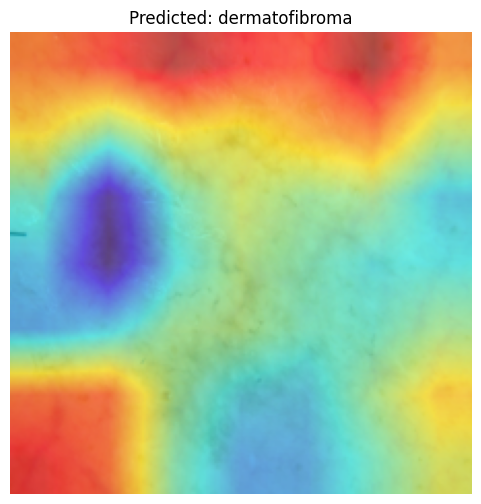

In [ ]:
# Overlay CAM di gambar asli
visualization = show_cam_on_image(img_for_cam, grayscale_cam, use_rgb=True)

# Tampilkan
plt.figure(figsize=(6, 6))
plt.imshow(visualization)
plt.title(f"Predicted: {train_dataset.classes[predicted_class]}")
plt.axis('off')
plt.show()

In [ ]:
# Inisialisasi heatmap total
avg_heatmap = np.zeros((224, 224))
num_images = 0

model.eval()

HybridModel(
  (efficientnet): EfficientNet(
    (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (bn1): BatchNormAct2d(
            32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
          (conv_pw

100%|██████████| 24/24 [12:03<00:00, 30.17s/it]


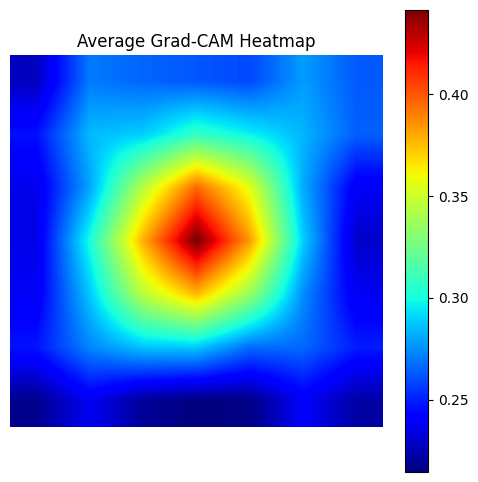

In [ ]:
for inputs, labels in tqdm(test_loader):  # bisa juga train_loader
    inputs = inputs.to(device)

    for i in range(inputs.size(0)):
        input_tensor = inputs[i].unsqueeze(0)
        rgb_img = input_tensor.squeeze().permute(1, 2, 0).cpu().numpy()
        rgb_img = (rgb_img * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])  # unnormalize
        rgb_img = np.clip(rgb_img, 0, 1)

        grayscale_cam = cam(input_tensor=input_tensor)[0]
        grayscale_cam_resized = cv2.resize(grayscale_cam, (224, 224))

        avg_heatmap += grayscale_cam_resized
        num_images += 1

# Rata-ratakan heatmap
avg_heatmap /= num_images

# Visualisasi heatmap rata-rata
plt.figure(figsize=(6, 6))
plt.imshow(avg_heatmap, cmap='jet')
plt.title("Average Grad-CAM Heatmap")
plt.axis('off')
plt.colorbar()
plt.show()

In [ ]:
def preprocess_image(image_path):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),  # [0, 1]
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])
    image = Image.open(image_path).convert('RGB')
    original = image.copy()
    return transform(image).unsqueeze(0), original  # Tensor, PIL

def show_gradcam_comparison(image_path, model, target_layer):
    # Preprocess input
    input_tensor, original_image = preprocess_image(image_path)
    input_tensor = input_tensor.to(next(model.parameters()).device)

    # Create Grad-CAM object
    cam = GradCAM(model=model, target_layers=[target_layer])
    targets = None  # or [ClassifierOutputTarget(class_idx)] if kamu mau spesifik

    # Generate heatmap
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]  # [0] untuk batch pertama
    rgb_image = np.array(original_image.resize((224, 224))).astype(np.float32) / 255.0

    # Grad-CAM Overlay
    cam_image = show_cam_on_image(rgb_image, grayscale_cam, use_rgb=True)

    # Plot side-by-side
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(original_image.resize((224, 224)))
    axes[0].set_title("Gambar Asli")
    axes[0].axis('off')

    axes[1].imshow(grayscale_cam, cmap='jet')
    axes[1].set_title("Grad-CAM Heatmap")
    axes[1].axis('off')

    axes[2].imshow(cam_image)
    axes[2].set_title("Overlay Grad-CAM")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

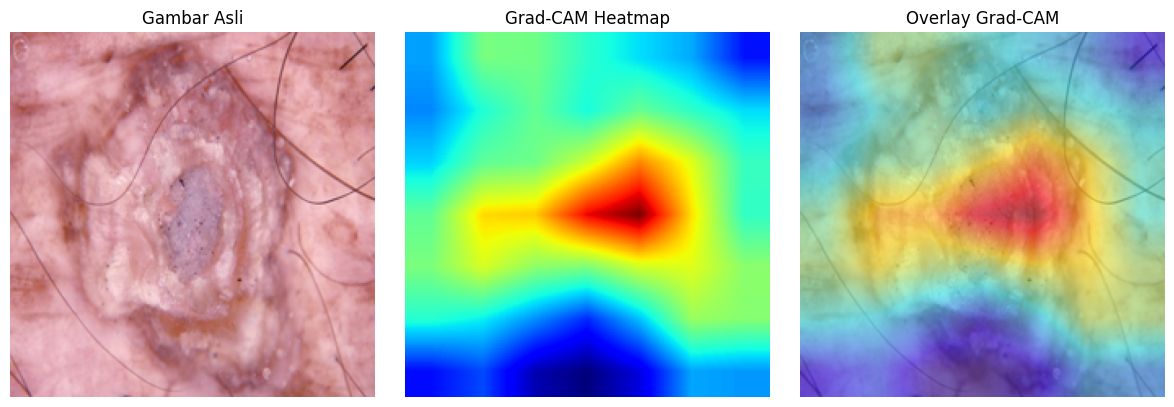

In [ ]:
image_path, _ = val_dataset.samples[1]
show_gradcam_comparison(image_path, model, target_layer=model.efficientnet.conv_head)